In [2]:
import DecisionTree
import pandas as pd
from nltk import ConfusionMatrix
from sklearn.compose import ColumnTransformer

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [3]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [4]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [5]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [6]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [7]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


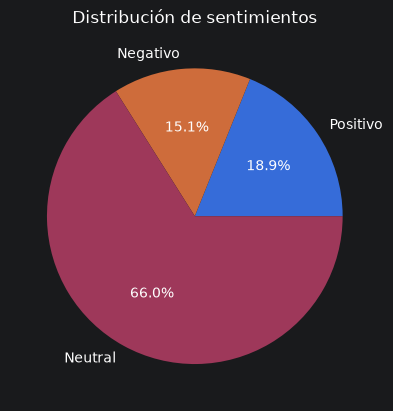

In [8]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


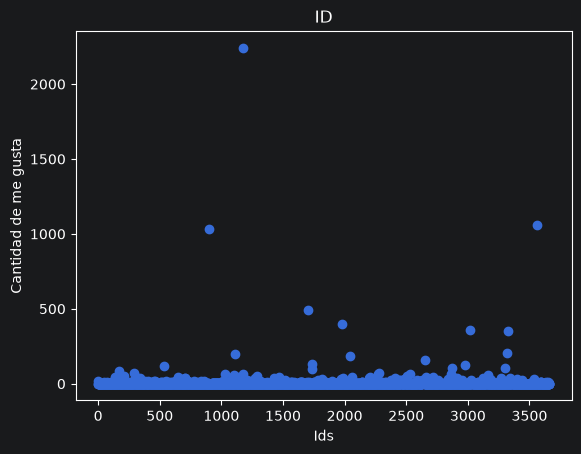

In [9]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


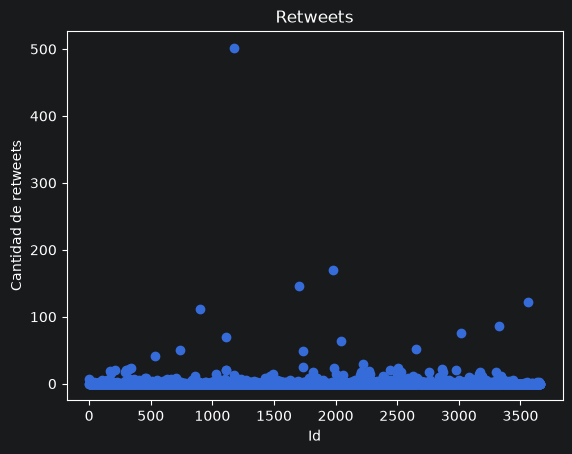

In [10]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


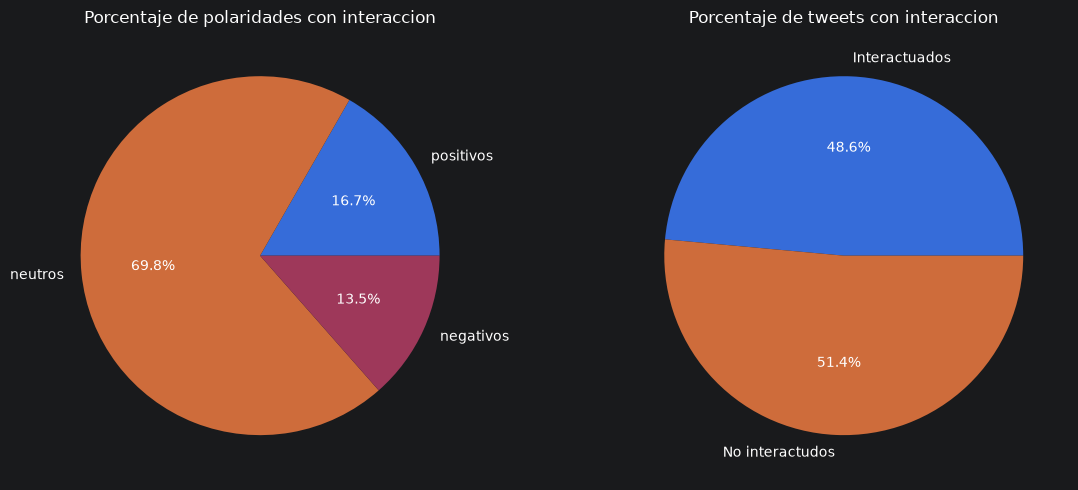

In [11]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [12]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["interrogation_count"] = df['text'].apply(lambda texto: texto.count('?') )
df["exclamation_count"] = df['text'].apply(lambda texto: texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [13]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

print("Urls: ", df['url_count'].sum())
print("Menciones: ", df['mention_count'].sum())
df.head()

Urls:  1389
Menciones:  3039


,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,interrogation_count,exclamation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0,0


In [14]:
import emoji
from emosent import get_emoji_sentiment_rank

def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

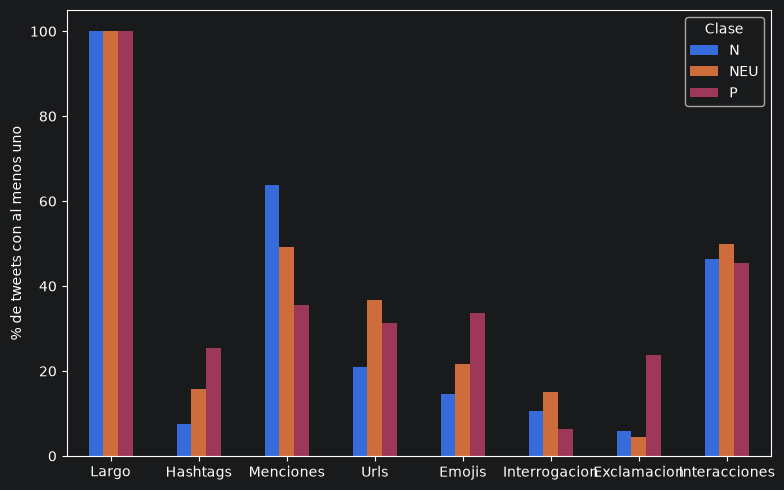

In [15]:
cols = {
    "length": "Largo",
    "hashtag_count": "Hashtags",
    "mention_count": "Menciones",
    "url_count": "Urls",
    "emoji_count": "Emojis",
    "interrogation_count": "Interrogacion",
    "exclamation_count": "Exclamacion",
    "tweet_interactions": "Interacciones"
}

# % de tweets de cada clase que tienen al menos 1 del elemento
pct = (df[list(cols)] > 0).groupby(df["polarity"]).mean() * 100
pct = pct.rename(columns=cols)

ax = pct.T.plot(kind="bar", figsize=(8, 5))
ax.set_ylabel("% de tweets con al menos uno")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.legend(title="Clase")
plt.tight_layout()
plt.show()

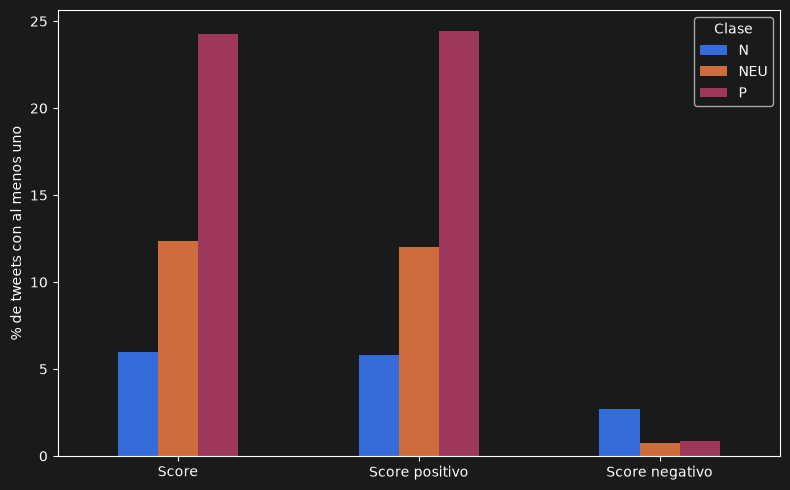

In [16]:
cols = {
    "emoji_score": "Score",
    "emoji_pos": "Score positivo",
    "emoji_neg": "Score negativo"
}

# % de tweets de cada clase que tienen al menos 1 del elemento
pct = (df[list(cols)] > 0).groupby(df["polarity"]).mean() * 100
pct = pct.rename(columns=cols)

ax = pct.T.plot(kind="bar", figsize=(8, 5))
ax.set_ylabel("% de tweets con al menos uno")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.legend(title="Clase")
plt.tight_layout()
plt.show()

In [17]:
from collections import Counter

no_encontrados = Counter()
for t in df["text"]:
    for e in emoji.emoji_list(str(t)):
        if get_emoji_sentiment_rank(e["emoji"]) is None:
            no_encontrados[e["emoji"]] += 1

print(no_encontrados.most_common(15))

[('🤖', 45), ('🤔', 35), ('➡️', 34), ('🤣', 31), ('🧵', 31), ('🧠', 15), ('⬇️', 14), ('👉🏻', 14), ('🔗', 14), ('🗣️', 13), ('🗣', 11), ('‼️', 11), ('🤓', 10), ('🤭', 10), ('👉🏼', 10)]


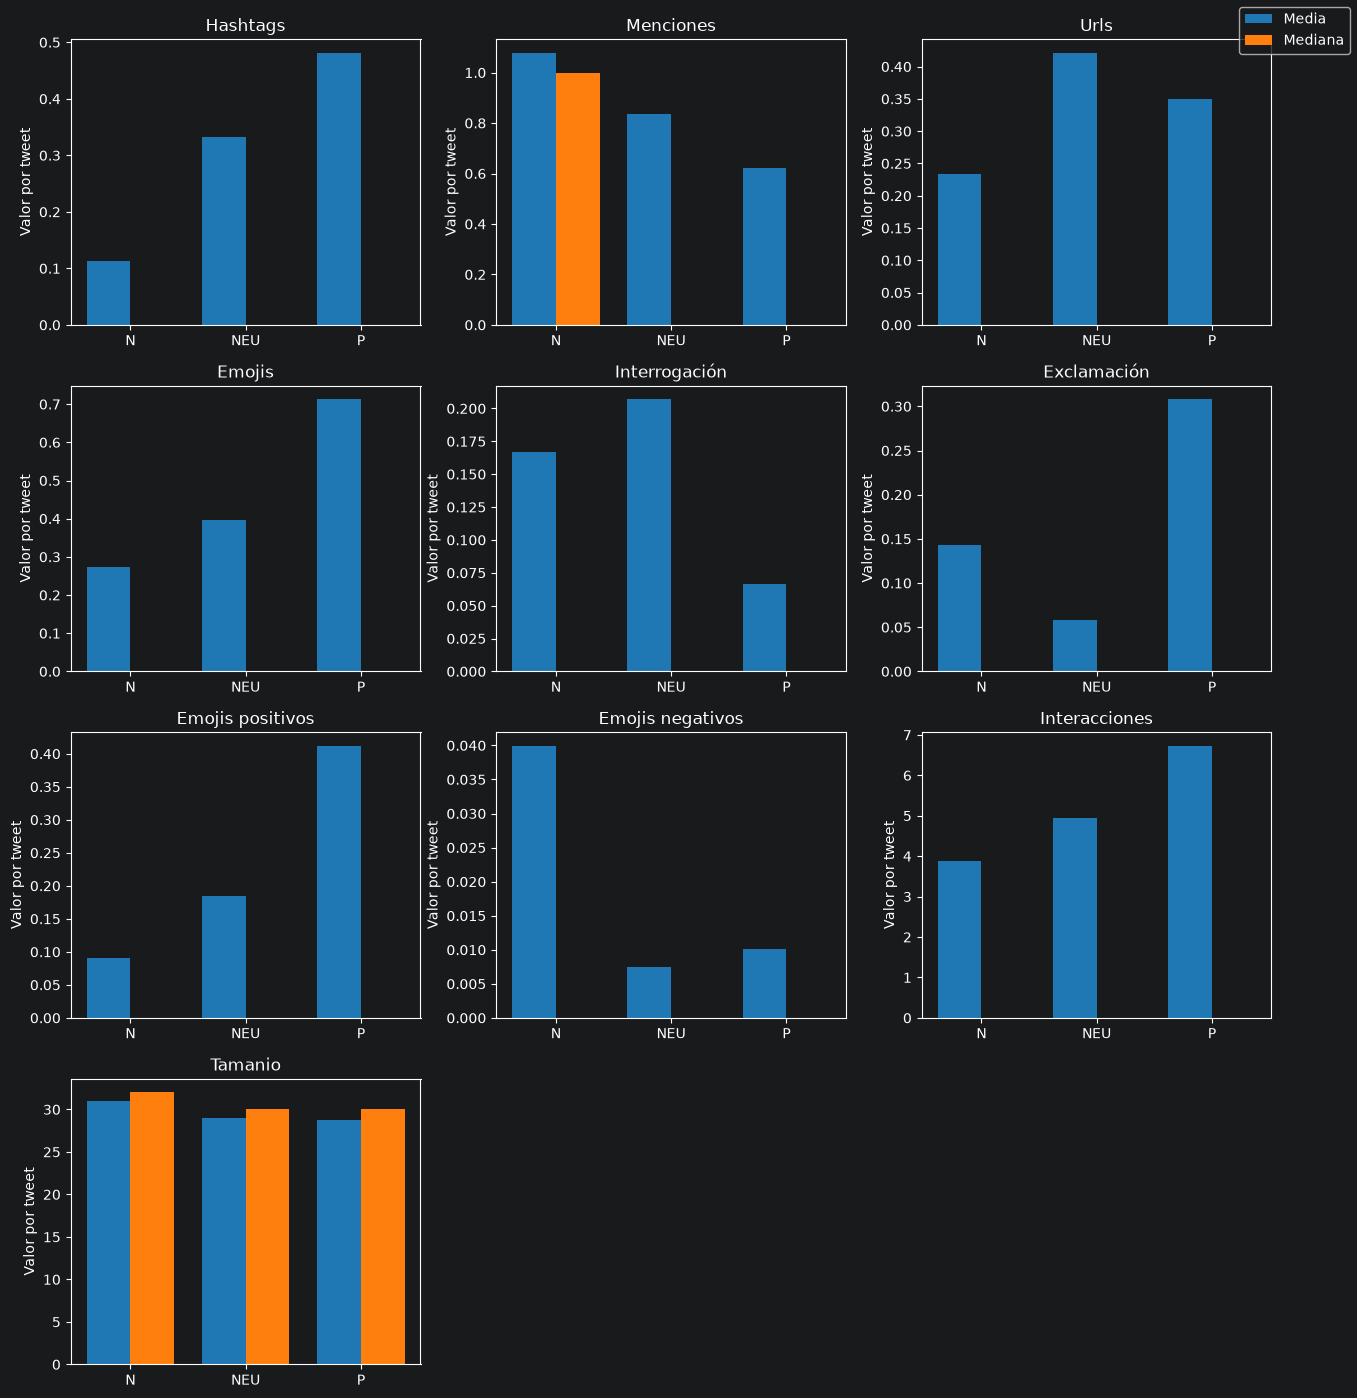

In [18]:
import numpy as np
import matplotlib.pyplot as plt

nombres = {
    "hashtag_count": "Hashtags",
    "mention_count": "Menciones",
    "url_count": "Urls",
    "emoji_count": "Emojis",
    "interrogation_count": "Interrogación",
    "exclamation_count": "Exclamación",
    "emoji_pos": "Emojis positivos",
    "emoji_neg": "Emojis negativos",
    "tweet_interactions": "Interacciones",
    "length": "Tamanio"
}

grupos = df.groupby("polarity")[list(nombres)]
medias = grupos.mean()
medianas = grupos.median()

clases = medias.index.tolist()
x = np.arange(len(clases))
ancho = 0.38

n = len(nombres)
ncols = 3
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, (col, titulo) in zip(axes, nombres.items()):
    ax.bar(x - ancho / 2, medias[col], ancho, label="Media", color="tab:blue")
    ax.bar(x + ancho / 2, medianas[col], ancho, label="Mediana", color="tab:orange")
    ax.set_title(titulo)
    ax.set_xticks(x)
    ax.set_xticklabels(clases)
    ax.set_ylabel("Valor por tweet")

for ax in axes[n:]:
    ax.axis("off")

# una sola leyenda para toda la figura
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")

plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.show()

In [19]:
df = df.drop(columns=["emoji_score", "emoji_count", "tweet_interactions", "mention_count",
                      "user_followers_count", "user_default_profile", "user_verified"
                      ])

In [20]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [21]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import string

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.base import BaseEstimator, TransformerMixin

PUNCT = set(string.punctuation) | set("¿¡«»“”‘’…")

# Palabras que NO se eliminan aunque estén en la lista de stopwords
KEEP = {"no", "ni", "sin", "nunca", "tampoco", "nada", "contra", "muy", "pero", "más", "menos"}
STOP_WORDS = set(stopwords.words("spanish")) - KEEP


class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None, ngram_range=(1, 1), remove_stopwords=True):
        self.method = method                      # None, "stem" o "lemma"
        self.ngram_range = ngram_range            # (1, 1) = solo palabras sueltas
        self.remove_stopwords = remove_stopwords  # True = saca stopwords (salvo KEEP)

    def fit(self, X, y=None):
        if self.method not in (None, "stem", "lemma"):
            raise ValueError("method debe ser None, 'stem' o 'lemma'")
        return self

    def _is_valid(self, token):
        if not token.strip() or all(c in PUNCT for c in token):
            return False
        if self.remove_stopwords and token in STOP_WORDS:
            return False
        return True

    def _ngrams(self, tokens):
        n_min, n_max = self.ngram_range
        out = []
        for n in range(n_min, n_max + 1):
            out += ["_".join(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
        return out

    def transform(self, X):
        X = list(X)

        if self.method == "lemma":
            import spacy
            nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
            token_lists = []
            for doc in nlp.pipe(X):
                # se filtra por el texto original y después se toma el lema
                token_lists.append([t.lemma_.lower() for t in doc if self._is_valid(t.text.lower())])
        else:
            token_lists = [
                [t for t in nltk.word_tokenize(text.lower(), language="spanish") if self._is_valid(t)]
                for text in X
            ]
            if self.method == "stem":
                stemmer = SnowballStemmer("spanish")
                token_lists = [[stemmer.stem(t) for t in toks] for toks in token_lists]

        return [" ".join(self._ngrams(toks)) for toks in token_lists]

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Usuario\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [22]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("lemma")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [23]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='all-MiniLM-L6-v2'):
        self.model_name = model_name
        self.model = None

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if self.model is None:
            self.model = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        return self.model.encode(list(X), show_progress_bar=False)


C:\Users\Usuario\Desktop\Facultad\4\cd\cienciaDeDatos\Tp_tweets\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [24]:
X_train.head()

,text,favorite_count,retweet_count,user_friends_count,user_favourites_count,user_statuses_count,length,hashtag_count,url_count,interrogation_count,exclamation_count,emoji_pos,emoji_neg
1468,La Agencia Española de Protección de Datos (AE...,1,0,7,0,173,19,2,0,0,0,0.0,0.0
3145,"Además, las empresas siempre necesitarán conte...",0,0,1,2,31,27,0,0,0,0,0.0,0.0
2137,MENCION Le he preguntado por Covid y su relaci...,2,0,295,15228,6816,17,0,0,0,0,0.0,0.0
3883,MENCION MENCION No se puede decir que van a se...,1,0,283,8406,16623,50,0,0,0,0,0.0,0.0
2562,MENCION MENCION MENCION Miralo desde el punto ...,0,0,79,374,2329,49,0,0,0,0,0.0,0.0


Definicion de columnas de texto y numericas

In [25]:
# Columna de texto y columnas numericas
text_col = "text"


num_cols = [
    "user_statuses_count", "length", "exclamation_count",
    "emoji_pos", "user_friends_count", "user_favourites_count", "emoji_neg",
    "favorite_count", "retweet_count", "hashtag_count", "url_count",
    "interrogation_count"
]


### Principales hiperparámetros de DecisionTreeClassifier

| Hiperparámetro | ¿Qué controla? | ¿Por qué afecta al rendimiento? |
|---|---|---|
| `max_depth` | Profundidad máxima del árbol. | Limita la complejidad y ayuda a evitar el *overfitting*. |
| `min_samples_leaf` | Mínimo de muestras que debe tener cada hoja. | Evita hojas con muy pocos ejemplos, que pueden representar patrones poco generalizables. |
| `min_samples_split` | Mínimo de muestras necesarias para dividir un nodo. | Evita divisiones cuando hay pocos ejemplos para justificarlas. |
| `criterion` | Criterio para medir la calidad de una división: `gini`, `entropy` o `log_loss`. | Influye en qué características y divisiones elige el árbol. |

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier

vectorizer_dt = Pipeline([
    ("cleaner", TextCleaner("stem")),
    ("vectorizer", TfidfVectorizer()),
])

preprocesador_dt = ColumnTransformer([
    ("text", vectorizer_dt, text_col),
    ("num", StandardScaler(), num_cols),
])

mejor_modelo_dt = DecisionTreeClassifier(
    max_depth=20,
    class_weight="balanced",
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

pipeline_dt = Pipeline([
    ('pre', preprocesador_dt),
    ('classifier', mejor_modelo_dt)
])

pipeline_dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['N','NEU','P']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['text','favorite_count','retweet_count',...,'exclamation_count', 'emoji_pos','emoji_neg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rema

Entrenamiento de estrategia One versus One, usando DecisionTree como modelo, optimizando la metrica f1. Se utiliza el mejor modelo de decision tree previamente obtenido.

In [30]:
from sklearn.multiclass import OneVsOneClassifier
from sklearn import clone

modelo_ovo_dt = Pipeline([
    ("pre", clone(preprocesador_dt)),
    ("classifier", OneVsOneClassifier(
        mejor_modelo_dt
    ))
])

modelo_ovo_dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['N','NEU','P']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['text','favorite_count','retweet_count',...,'exclamation_count', 'emoji_pos','emoji_neg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rema

Entrenamiento de estrategia One versus All, usando DecisionTree como modelo, optimizando la metrica f1. Se utiliza el mejor modelo de decision tree previamente obtenido.

In [31]:
from sklearn.multiclass import OneVsRestClassifier

# Modelo 3: One-vs-Rest (One-vs-All)
modelo_ova_dt = Pipeline([
    ("pre", clone(preprocesador_dt)),
    ("classifier", OneVsRestClassifier(
        mejor_modelo_dt
    ))
])

modelo_ova_dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U3](3,)","['N','NEU','P']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['text','favorite_count','retweet_count',...,'exclamation_count', 'emoji_pos','emoji_neg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('text', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

En esta seccion, se pueden observar la curva de complejidad del hiperparamentro MAX_DEPTH de los 3 modelos, en cuanto al set de entrenamiento y validacion, en relacion con la metrica f1.

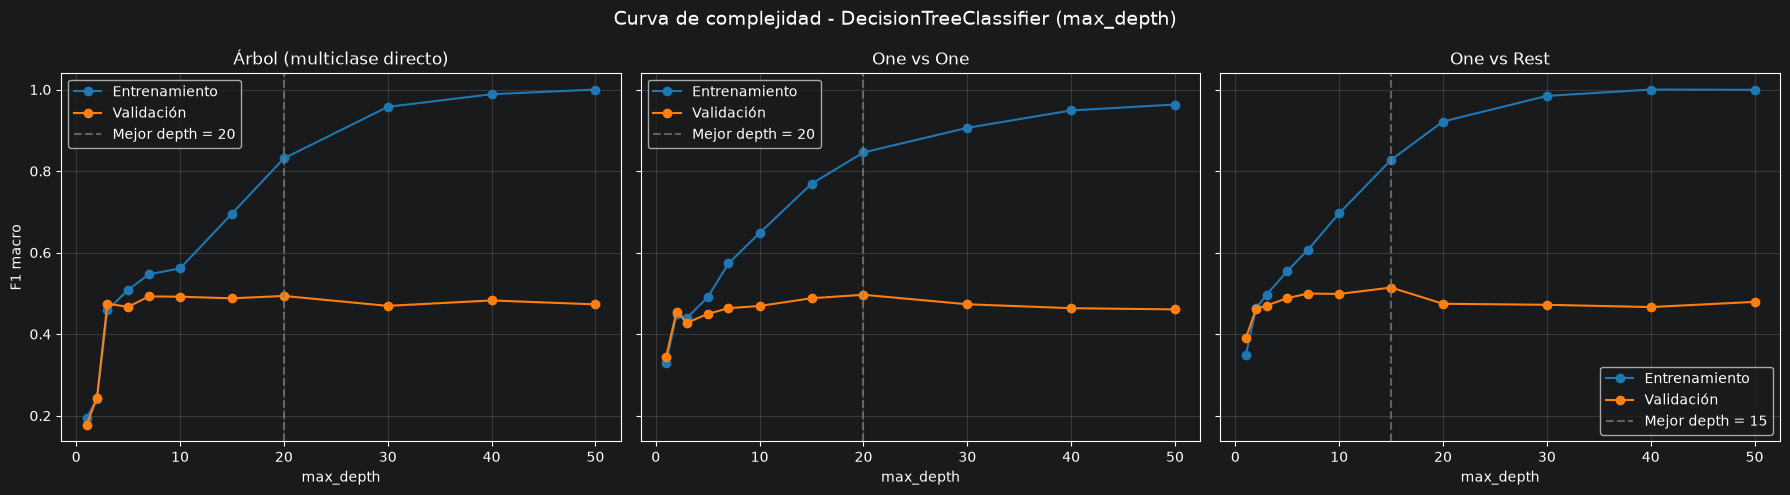

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import f1_score, classification_report

# Preprocesador ya ajustado sobre X_train (es el mismo en los 3 pipelines)
pre = pipeline_dt.named_steps["pre"]
Xtr = pre.transform(X_train)
Xva = pre.transform(X_val)

rango_depth = [1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50]

modelos = {
    "Árbol (multiclase directo)": (pipeline_dt,    "max_depth"),
    "One vs One":                 (modelo_ovo_dt,  "estimator__max_depth"),
    "One vs Rest":                (modelo_ova_dt,  "estimator__max_depth"),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (nombre, (modelo, param)) in zip(axes, modelos.items()):
    clf_base = modelo.named_steps["classifier"]
    f1_train, f1_val = [], []

    for d in rango_depth:
        clf = clone(clf_base).set_params(**{param: d})
        clf.fit(Xtr, y_train)
        f1_train.append(f1_score(y_train, clf.predict(Xtr), average="macro"))
        f1_val.append(f1_score(y_val, clf.predict(Xva), average="macro"))

    f1_train, f1_val = np.array(f1_train), np.array(f1_val)

    ax.plot(rango_depth, f1_train, "o-", label="Entrenamiento", color="tab:blue")
    ax.plot(rango_depth, f1_val, "o-", label="Validación", color="tab:orange")

    mejor = rango_depth[f1_val.argmax()]
    ax.axvline(mejor, color="gray", linestyle="--", alpha=0.7,
               label=f"Mejor depth = {mejor}")

    ax.set_title(nombre)
    ax.set_xlabel("max_depth")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("F1 macro")
fig.suptitle("Curva de complejidad - DecisionTreeClassifier (max_depth)", fontsize=14)
plt.tight_layout()
plt.show()

En esta seccion, se testean los modelos con el dataset de test

Text(0.5, 1.0, 'Estrategia One versus All')

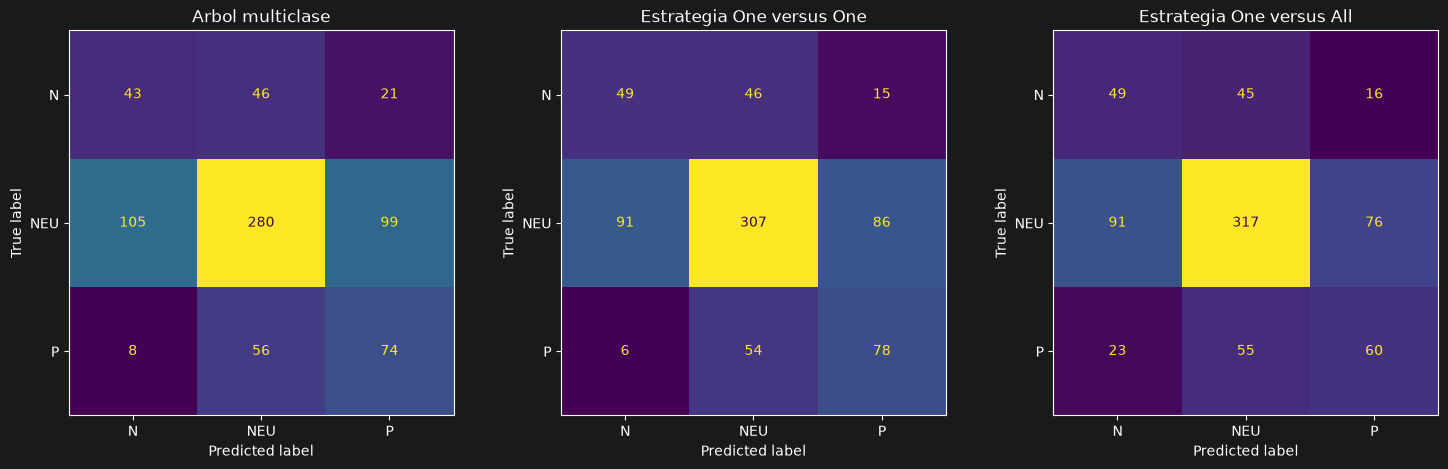

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

y_pred_dt_test = pipeline_dt.predict(X_test)

#Matriz de confusion en validacion de decision tree
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt_test, ax=axes[0], colorbar=False)
axes[0].set_title("Arbol multiclase")

y_pred_ovo_test = modelo_ovo_dt.predict(X_test)

#Matriz de confusion en validacion con estrategia One versus One
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ovo_test, ax=axes[1], colorbar=False)
axes[1].set_title("Estrategia One versus One")

y_pred_ova_test = modelo_ova_dt.predict(X_test)

#Matriz de confusion en validacion con estrategia One versus All
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_ova_test, ax=axes[2], colorbar=False)
axes[2].set_title("Estrategia One versus All")

In [36]:
from sklearn.metrics import f1_score

f1_dt = f1_score(y_test, y_pred_dt_test, average="macro")
print("F1 en decision tree: ", f1_dt)

f1_ovo = f1_score(y_test, y_pred_ova_test, average="macro")
print("F1 en One versus One ", f1_ovo)

f1_ova = f1_score(y_test, y_pred_ova_test, average="macro")
print("F1 en One versus All: ", f1_ova)

F1 en decision tree:  0.4719142244715548
F1 en One versus One  0.49214335317898406
F1 en One versus All:  0.49214335317898406


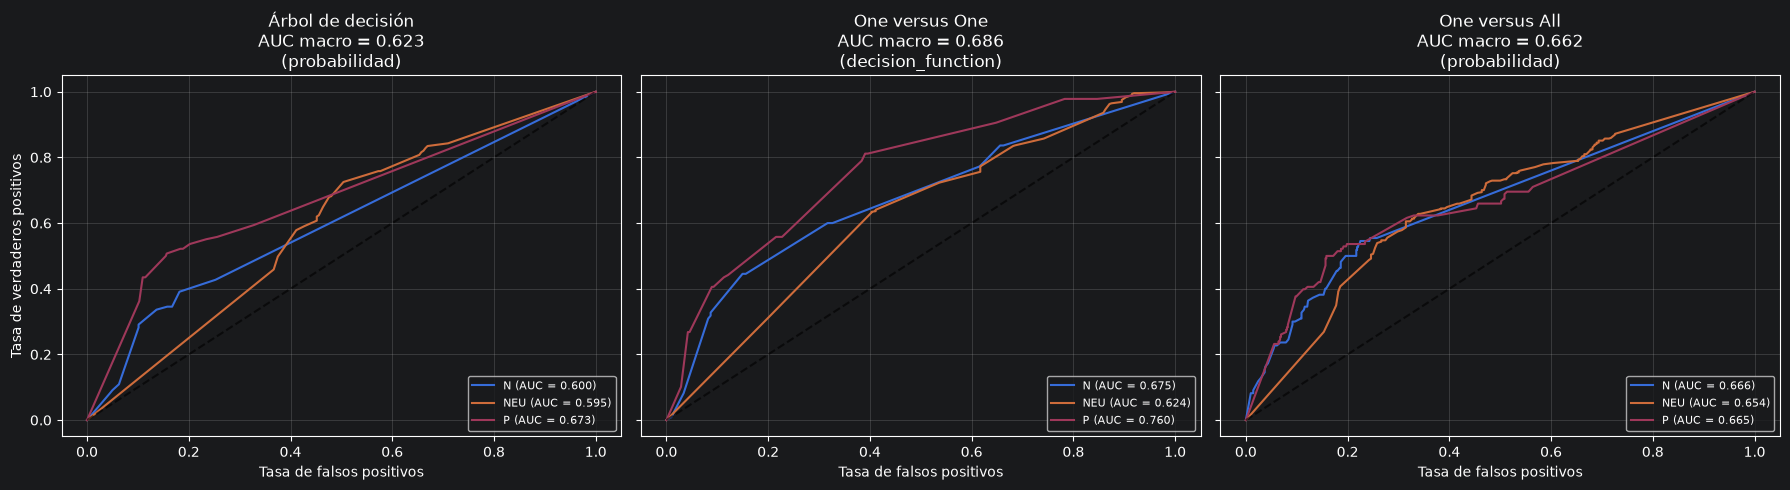

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

modelos = {
    "Árbol de decisión": pipeline_dt,   # el pipeline completo, no mejor_modelo_dt
    "One versus One": modelo_ovo_dt,
    "One versus All": modelo_ova_dt,
}

def obtener_puntajes(modelo, X):
    """predict_proba si existe; si no (OvO), decision_function."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X), "probabilidad"
    return modelo.decision_function(X), "decision_function"

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (nombre, modelo) in zip(axes, modelos.items()):
    clases = list(modelo.classes_)
    y_test_bin = label_binarize(y_test, classes=clases)
    y_score, origen = obtener_puntajes(modelo, X_test)

    for i, clase in enumerate(clases):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        ax.plot(fpr, tpr, label=f"{clase} (AUC = {auc(fpr, tpr):.3f})")

    auc_macro = roc_auc_score(y_test_bin, y_score, average="macro")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.6)
    ax.set_title(f"{nombre}\nAUC macro = {auc_macro:.3f}\n({origen})")
    ax.set_xlabel("Tasa de falsos positivos")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_ylabel("Tasa de verdaderos positivos")
plt.tight_layout()
plt.show()

In [40]:
from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred_ovo_test)
print(report)

              precision    recall  f1-score   support

           N       0.34      0.45      0.38       110
         NEU       0.75      0.63      0.69       484
           P       0.44      0.57      0.49       138

    accuracy                           0.59       732
   macro avg       0.51      0.55      0.52       732
weighted avg       0.63      0.59      0.61       732



Conclusion: el modelo de decision tree, tiene dificultades para distinguir a las muestras de las clases positivas y negativas de las muestras de las clases neutras. A pesar de eso, se llego a la conclusion que con una estrategia de One versus One es una mejor solucion al problema, facilitando al modelo la distincion de las clases.

En esta seccion se deja documentado el grid search en donde se buscaron los hiperparametros optimos que optimizaban la metrica f1.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Tres variantes para la rama de texto
text_bow = Pipeline([
    ("cleaner", TextCleaner("lemma")),
    ("vectorizer", CountVectorizer()),
])
text_tfidf = Pipeline([
    ("cleaner", TextCleaner("lemma")),
    ("vectorizer", TfidfVectorizer()),
])
text_emb = EmbeddingTransformer()

# Un único preprocesador y un único pipeline
preprocesador = ColumnTransformer([
    ("text", text_bow, text_col),
    ("num", StandardScaler(), num_cols),
])

pipeline = Pipeline([
    ("pre", preprocesador),
    ("classifier", DecisionTreeClassifier(random_state=42)),
], memory="cache_dir")

param_grid = [
    {
        "pre__text": [text_bow, text_tfidf],
        "pre__text__cleaner__method": ["stem", "lemma"],
        "pre__text__cleaner__ngram_range": [(1,1), (1, 2)],
        "classifier__max_depth": [5, 10, 20],
        "classifier__min_samples_leaf": [1, 5, 10],
        "classifier__min_samples_split": [2, 5, 10],
        'classifier__class_weight': ["balanced"],
    },
    {
        "pre__text": [text_emb],
        "classifier__max_depth": [5, 10, 20],
        "classifier__min_samples_leaf": [1, 5, 10, 20],
        'classifier__class_weight': ["balanced"],
    },
]

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

#Entrenamiento del modelo
grid_search = GridSearchCV(pipeline, param_grid, cv=skf, scoring="f1_macro", n_jobs=1, verbose=1)
grid_search.fit(X_train, y_train)
print(grid_search.best_score_)
print(grid_search.best_params_)

# {'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'pre__text': Pipeline(steps=[('cleaner', TextCleaner(method='lemma')),
#                 ('vectorizer', TfidfVectorizer())]), 'pre__text__cleaner__method': 'stem', 'pre__text__cleaner__ngram_range': (1, 2)}

En esta seccion se investigo que features son mas importantes para evitar tener mas features de las necesarias.

In [ ]:
from sklearn.inspection import permutation_importance

resultado = permutation_importance(
    grid_search.best_estimator_,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

import pandas as pd

importancias = pd.DataFrame({
    "columna": X_test.columns,
    "importancia": resultado.importances_mean,
    "desviacion": resultado.importances_std
})

importancias = importancias.sort_values(
    by="importancia",
    ascending=False
)

print(importancias)

#                   columna  importancia  desviacion
# 0                    text     0.069388    0.011475
# 6     user_statuses_count     0.037262    0.013479
# 10                 length     0.024141    0.008304
# 15      exclamation_count     0.021258    0.007140
# 17              emoji_pos     0.016195    0.008462
# 4      user_friends_count     0.011459    0.010958
# 5   user_favourites_count     0.008736    0.004748
# 18              emoji_neg     0.004236    0.001043
# 1          favorite_count     0.002276    0.001473
# 2           retweet_count     0.001735    0.002396
# 11          hashtag_count     0.000971    0.001653
# 13              url_count     0.000552    0.000930
# 14    interrogation_count     0.000197    0.001939
# 7           user_verified     0.000000    0.000000
# 8    user_default_profile     0.000000    0.000000
# 3    user_followers_count    -0.000925    0.009102
# 12          mention_count    -0.001094    0.001816
# 9      tweet_interactions    -0.001735    0.004329
# 16            emoji_count    -0.002579    0.000508